### Scenariusz symulacji

Scenariusz przedstawia dynamiczną symulację propagacji fal radiowych w modelu sceny 3D kampus AGH. W scenariuszu definiowany jest nadajnik, odbiornik oraz obiekt reprezentujący człowieka, a następnie w kolejnych iteracjach jeden z obiektów jest przesuwany o zadany wektor. Dla każdej pozycji sceny wyznaczane są ścieżki propagacji z uwzględnieniem odbić, rozproszenia i refrakcji, po czym renderowana jest mapa radiowa aktualizowana w czasie symulacji.

In [2]:
# Importowanie najwazniejszych bibliotek
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# Importowanie najwazniejszych komponentow Sionna RT
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMaterial

my_cam = Camera(position=[-100, -140, 150.0],
                look_at=[-40, -20, 30])

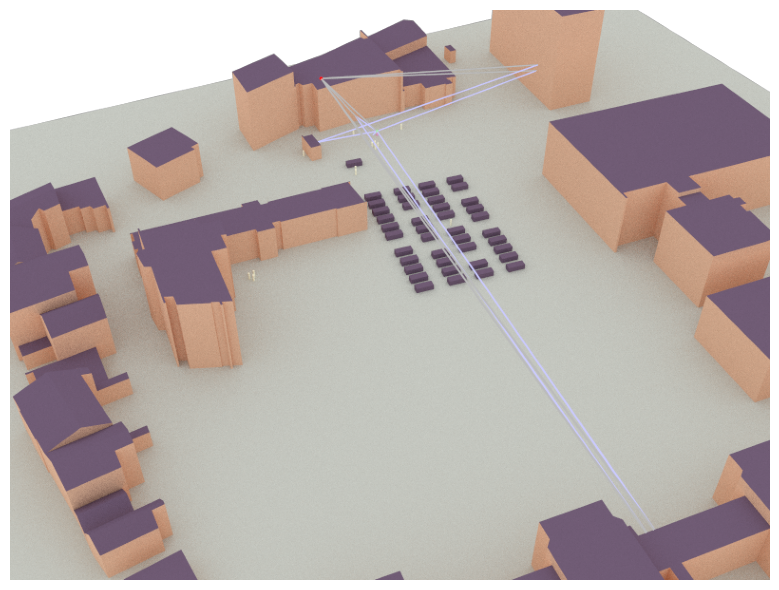

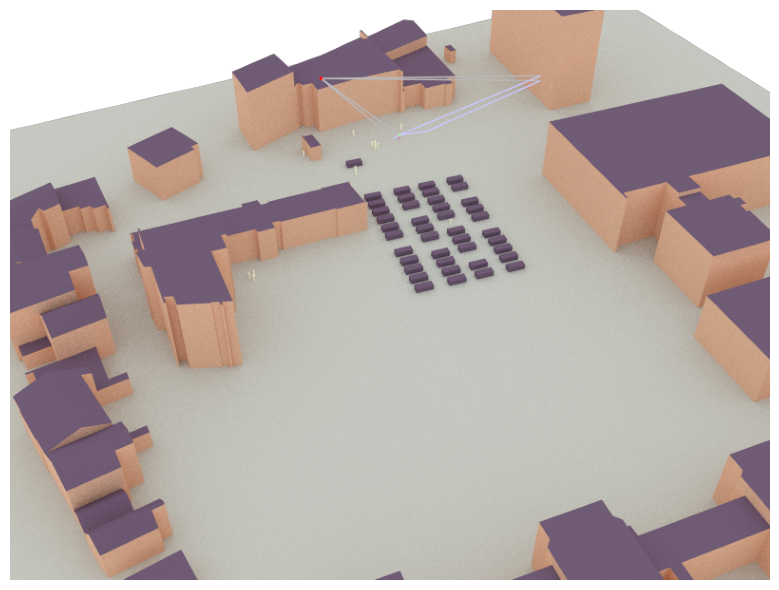

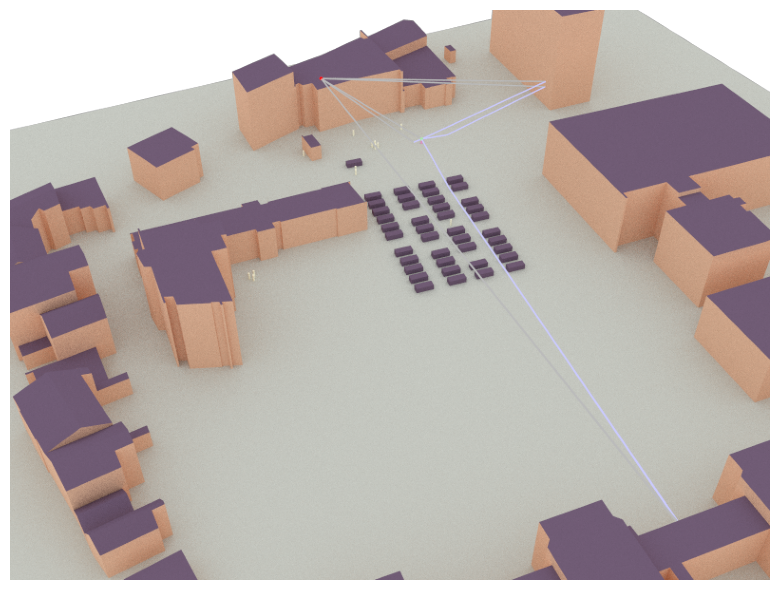

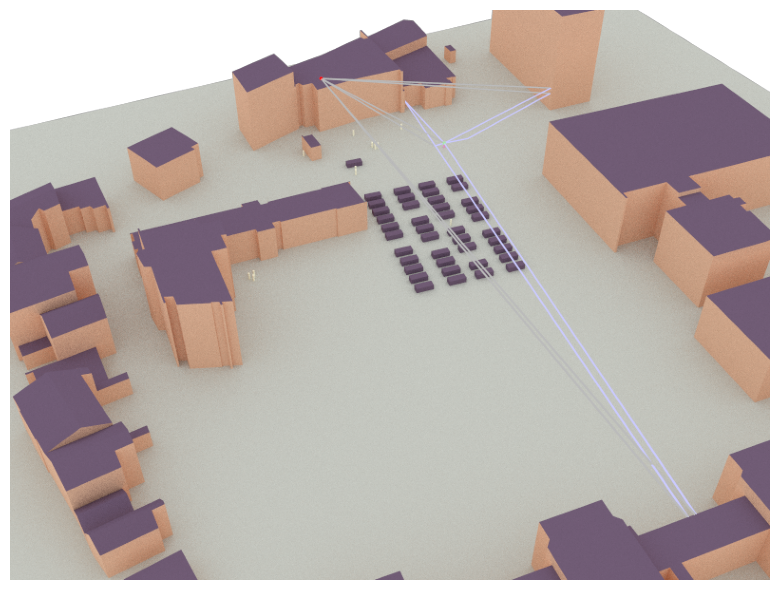

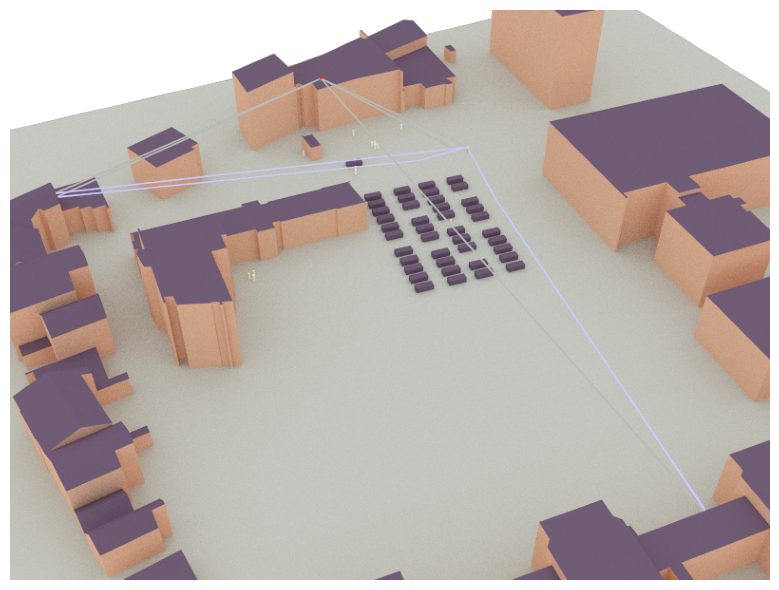

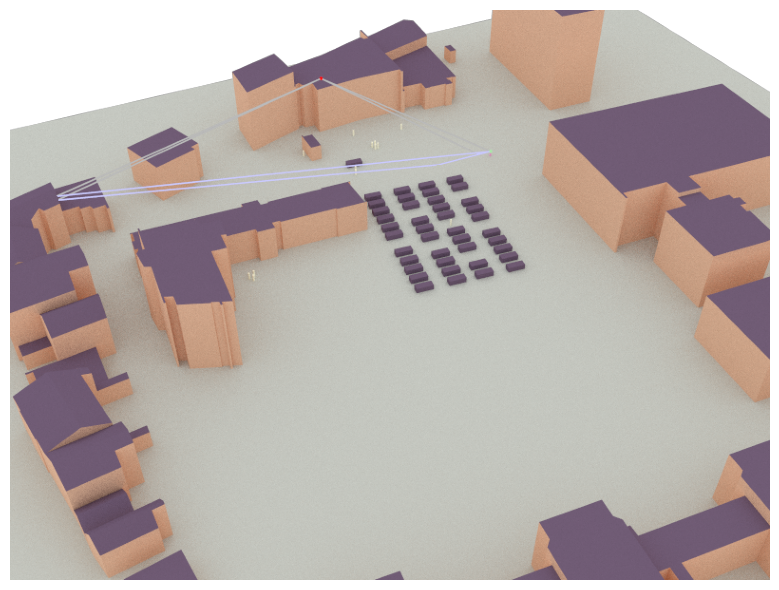

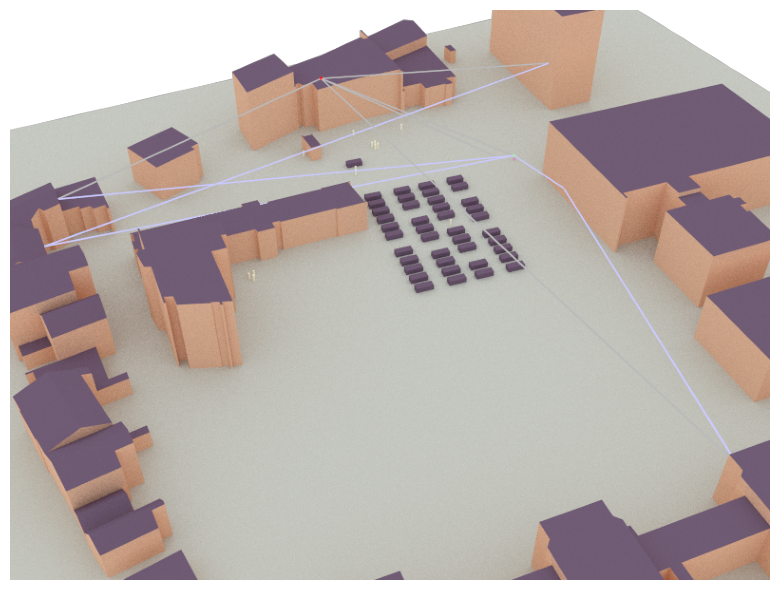

In [3]:
scene = load_scene("./OpenStreetMap/kampus_AGH_B9_test/Kampus_AGH_B9_test.xml", merge_shapes=False)

scene.frequency = 3.6e9

# Tworzenie materiału udającego ludzkie ciało
human_flesh = RadioMaterial("human_flesh", relative_permittivity=45.0, conductivity=1.5)

if "human_flesh" not in scene.radio_materials:
    scene.add(human_flesh)

    for name, obj in scene.objects.items():
        if "Czlowiek" in name:
            obj.radio_material = human_flesh

if "pink_highlight" not in scene.radio_materials:
    rozowy_material = RadioMaterial(name="pink_highlight",
                                    relative_permittivity=1.0, 
                                    conductivity=0,
                                    color=[1.0, 0.4, 0.8])

    scene.add(rozowy_material)

    scene.get("Czlowiek_003").radio_material = rozowy_material

# konfiguracja parametrów anteny dla nadajnika
scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="V")
# Tworzenie nadajnika
tx = Transmitter(name="tx",
                 position=[-9.169, 87.045, 17.500],
                 display_radius=0.5)

# dodanie instancji nadajnika do sceny
scene.add(tx)

# konfiguracja parametrów anteny dla odbiornika
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="dipole",
                             polarization="cross")

rx_antena = Receiver(name="rx1",
              position=[4.08414, 76.9666, 1.500],
              display_radius=0.5)

scene.add(rx_antena)

czlowiek = scene.get("Czlowiek_003")
antena = scene.get("rx1")

p_solver = PathSolver()

# Konfiguracja ruchu
displacement_vec = np.array([5, -5, 0.0]) # Idziemy 1m w osi X
num_steps = 7

for i in range(num_steps):
    
    paths = p_solver(scene=scene,
                 max_depth=3,
                 samples_per_src=1_000_000,
                 los=True,
                 specular_reflection=True,
                 diffuse_reflection=True,
                 refraction=True,
                 synthetic_array=False,
                 seed=41)   
    
    # Renderowanie Mapy
    scene.render(camera=my_cam, 
                 paths=paths, 
                 rm_show_color_bar=True,
                 rm_vmax=-40, 
                 rm_vmin=-120,
                 resolution=(800, 600)) 
    plt.show()

    # ruch człowieka i anteny
    pozycja_c = czlowiek.position
    pozycja_a = antena.position

    czlowiek.position = pozycja_c + displacement_vec
    antena.position = pozycja_a + displacement_vec